# **Install Requirements**

In [1]:

import sys
import subprocess

# Install required packages
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "opencv-contrib-python-headless>=4.8,<5",
    "scikit-learn>=1.3",
    "matplotlib>=3.7",
    "pandas>=2",
    "tqdm>=4.66"
])

# Import libraries
import torch
import torchvision
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

assert (
    hasattr(cv2, "ximgproc")
    and hasattr(cv2.ximgproc, "segmentation")
), "Selective Search is unavailable. Check OpenCV installation."


PyTorch: 2.11.0+cu130
TorchVision: 0.26.0+cu130
OpenCV: 4.14.0
GPU available: True


# **Import Libraries and Set Configuration**

In [2]:

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import urllib.request
import zipfile
import random
import time
import os

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset configuration
ROOT = Path("/content/rcnn_lab")
ROOT.mkdir(exist_ok=True, parents=True)

MAX_IMAGES = 40
MAX_PROPOSALS = 120
SIZE = 384

print("Configuration completed.")


Using device: cuda
GPU: Tesla T4
Configuration completed.


# **Download COCO128 Dataset**

In [3]:

URL = (
    "https://github.com/ultralytics/assets/"
    "releases/download/v0.0.0/coco128.zip"
)

archive = ROOT / "coco128.zip"

# Download and extract dataset
if not (ROOT / "coco128" / "images" / "train2017").exists():

    if not archive.exists():
        print("Downloading COCO128...")
        urllib.request.urlretrieve(URL, archive)

    print("Extracting dataset...")

    with zipfile.ZipFile(archive) as z:
        z.extractall(ROOT)

IMG_DIR = ROOT / "coco128" / "images" / "train2017"
LBL_DIR = ROOT / "coco128" / "labels" / "train2017"

# Selected COCO classes
COCO_CLASSES = {
    0: "person",
    2: "car",
    16: "dog"
}


def load_record(path):

    image = cv2.imread(str(path))

    if image is None:
        return None

    h, w = image.shape[:2]

    boxes = []

    label_path = LBL_DIR / (path.stem + ".txt")

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            vals = line.strip().split()

            if len(vals) != 5:
                continue

            cls = int(float(vals[0]))

            if cls not in COCO_CLASSES:
                continue

            xc, yc, bw, bh = map(float, vals[1:])

            x1 = max(0, (xc - bw / 2) * w)
            y1 = max(0, (yc - bh / 2) * h)

            x2 = min(w, (xc + bw / 2) * w)
            y2 = min(h, (yc + bh / 2) * h)

            if x2 > x1 and y2 > y1:

                boxes.append((
                    np.array(
                        [x1, y1, x2, y2],
                        dtype=np.float32
                    ),
                    cls
                ))

    return {
        "path": path,
        "boxes": boxes
    }


# Read images and annotations
records = [
    load_record(p)
    for p in sorted(IMG_DIR.glob("*"))
    if p.suffix.lower() in (".jpg", ".jpeg", ".png")
]

records = [
    r for r in records
    if r is not None and r["boxes"]
]

print("Images with selected classes:", len(records))

object_counts = Counter(
    cls
    for record in records
    for _, cls in record["boxes"]
)

print("Object counts:", dict(object_counts))

assert len(records) >= 10, (
    "Not enough labeled images. Check dataset extraction."
)

# Split by image
train_records, test_records = train_test_split(
    records,
    test_size=0.25,
    random_state=SEED
)

train_records = train_records[:MAX_IMAGES]

test_records = test_records[
    :max(6, MAX_IMAGES // 4)
]

print("Training images:", len(train_records))
print("Testing images:", len(test_records))


Extracting dataset...
Images with selected classes: 75
Object counts: {0: 254, 16: 9, 2: 46}
Training images: 40
Testing images: 10


# **Visualize Ground Truth Boxes**

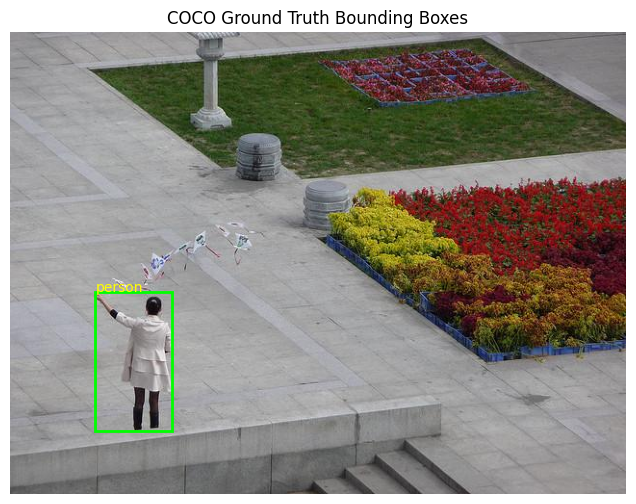

In [4]:

from matplotlib.patches import Rectangle

record = train_records[0]

image = cv2.cvtColor(
    cv2.imread(str(record["path"])),
    cv2.COLOR_BGR2RGB
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.imshow(image)

for box, cls in record["boxes"]:

    x1, y1, x2, y2 = box

    ax.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2
        )
    )

    ax.text(
        x1,
        y1,
        COCO_CLASSES[cls],
        color="yellow",
        fontsize=10
    )

ax.set_title("COCO Ground Truth Bounding Boxes")
ax.axis("off")

plt.savefig(
    "/content/rcnn_lab/ground_truth.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# **Resize Images and Bounding Boxes**

In [5]:

def prepare_image(record):

    raw = cv2.cvtColor(
        cv2.imread(str(record["path"])),
        cv2.COLOR_BGR2RGB
    )

    h, w = raw.shape[:2]

    resized = cv2.resize(
        raw,
        (SIZE, SIZE)
    )

    gt = [
        (
            np.array([
                b[0] * SIZE / w,
                b[1] * SIZE / h,
                b[2] * SIZE / w,
                b[3] * SIZE / h
            ], dtype=np.float32),
            c
        )
        for b, c in record["boxes"]
    ]

    return resized, gt


sample, gt = prepare_image(train_records[0])

print("Resized image shape:", sample.shape)
print("Number of ground-truth boxes:", len(gt))


Resized image shape: (384, 384, 3)
Number of ground-truth boxes: 1


# **Selective Search Region Proposals**

In [6]:

def selective_proposals(image, limit=MAX_PROPOSALS):

    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()

    ss.setBaseImage(
        cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    )

    ss.switchToSelectiveSearchFast()

    rects = ss.process()

    boxes = []
    seen = set()

    for x, y, w, h in rects:

        if w * h < 32 * 32 or w < 20 or h < 20:
            continue

        box = (
            int(x),
            int(y),
            int(min(x + w, SIZE)),
            int(min(y + h, SIZE))
        )

        if (
            box not in seen
            and box[2] > box[0]
            and box[3] > box[1]
        ):

            seen.add(box)
            boxes.append(box)

        if len(boxes) >= limit:
            break

    return np.array(
        boxes,
        dtype=np.float32
    ).reshape(-1, 4)


sample, gt = prepare_image(train_records[0])

start = time.perf_counter()

proposals = selective_proposals(sample)

proposal_time = time.perf_counter() - start

print("Number of proposals:", len(proposals))
print(f"Selective Search time: {proposal_time:.3f} seconds")


Number of proposals: 120
Selective Search time: 2.255 seconds


# **Visualize Region Proposals**

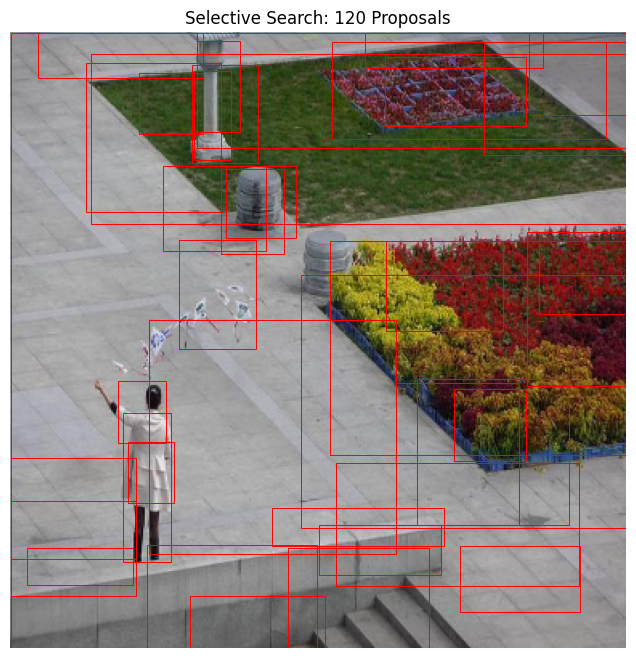

In [7]:

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(sample)

for x1, y1, x2, y2 in proposals[:40]:

    ax.add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=0.7
        )
    )

ax.set_title(
    f"Selective Search: {len(proposals)} Proposals"
)

ax.axis("off")

plt.savefig(
    "/content/rcnn_lab/selective_search.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# **Intersection over Union (IoU)**

In [8]:

def iou(box_a, box_b):

    xa = max(box_a[0], box_b[0])
    ya = max(box_a[1], box_b[1])

    xb = min(box_a[2], box_b[2])
    yb = min(box_a[3], box_b[3])

    intersection = (
        max(0, xb - xa) *
        max(0, yb - ya)
    )

    area_a = (
        max(0, box_a[2] - box_a[0]) *
        max(0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0, box_b[2] - box_b[0]) *
        max(0, box_b[3] - box_b[1])
    )

    union = area_a + area_b - intersection

    return float(
        intersection / max(union, 1e-8)
    )


if len(proposals) > 0 and len(gt) > 0:

    value = iou(
        proposals[0],
        gt[0][0]
    )

    print("IoU value:", round(value, 3))


IoU value: 0.038


# **Training Region Labeling**

In [9]:

BACKGROUND = -1

TRAIN_MAX_NEG = 30


def label_proposal(box, gt):

    if not gt:
        return BACKGROUND

    matches = [
        (iou(box, gbox), cls)
        for gbox, cls in gt
    ]

    score, cls = max(
        matches,
        key=lambda t: t[0]
    )

    if score >= 0.5:
        return cls

    if score < 0.2:
        return BACKGROUND

    return None


def build_training_rois(records):

    patches = []
    labels = []

    for rec in tqdm(records, desc="Preparing training regions"):

        image, gt = prepare_image(rec)

        regions = selective_proposals(image)

        # Add ground-truth boxes as training positives
        for box, cls in gt:

            x1, y1, x2, y2 = np.round(box).astype(int)

            if x2 - x1 >= 8 and y2 - y1 >= 8:

                patches.append(
                    image[y1:y2, x1:x2]
                )

                labels.append(cls)

        neg = []

        for box in regions:

            cls = label_proposal(box, gt)

            if cls is None:
                continue

            x1, y1, x2, y2 = np.round(box).astype(int)

            if x2 - x1 < 8 or y2 - y1 < 8:
                continue

            roi = image[y1:y2, x1:x2]

            if cls == BACKGROUND:

                neg.append(roi)

            else:

                patches.append(roi)
                labels.append(cls)

        random.shuffle(neg)

        for roi in neg[:TRAIN_MAX_NEG]:

            patches.append(roi)
            labels.append(BACKGROUND)

    return patches, np.array(labels, dtype=int)


train_patches, y_train = build_training_rois(
    train_records
)

print(
    "Training labels:",
    dict(Counter(y_train))
)

assert len(np.unique(y_train)) >= 2, (
    "Training requires at least two classes."
)


Preparing training regions:   0%|          | 0/40 [00:00<?, ?it/s]

Training labels: {np.int64(0): 196, np.int64(-1): 1200, np.int64(16): 30, np.int64(2): 9}


# **CNN Feature Extraction with ResNet18**

In [10]:

from PIL import Image

from torch.utils.data import DataLoader, Dataset
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

backbone = models.resnet18(
    weights=weights
)

# Remove final classification layer
backbone.fc = torch.nn.Identity()

backbone = backbone.to(device).eval()

preprocess = weights.transforms()


class ROIDataset(Dataset):

    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        return preprocess(
            Image.fromarray(self.images[index])
        )


@torch.no_grad()
def extract_features(patches, batch_size=32):

    if not patches:

        return np.empty(
            (0, 512),
            dtype=np.float32
        )

    loader = DataLoader(
        ROIDataset(patches),
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    result = []

    for batch in tqdm(
        loader,
        desc="Extracting CNN features",
        leave=False
    ):

        features = backbone(
            batch.to(device)
        )

        result.append(
            features.cpu().numpy()
        )

    return np.concatenate(
        result,
        axis=0
    )


X_train = extract_features(train_patches)

print("Feature matrix shape:", X_train.shape)
print("Feature dimension:", X_train.shape[1])


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 131MB/s]


Extracting CNN features:   0%|          | 0/45 [00:00<?, ?it/s]

Feature matrix shape: (1435, 512)
Feature dimension: 512


# **Train Linear SVM Classifier**

In [11]:

from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

svm = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        max_iter=6000,
        random_state=SEED
    )
)

# Train classifier
svm.fit(X_train, y_train)

print(
    "Learned classes:",
    svm.named_steps["linearsvc"].classes_
)

print("Training classification report:")

print(
    classification_report(
        y_train,
        svm.predict(X_train),
        zero_division=0
    )
)


Learned classes: [-1  0  2 16]
Training classification report:
              precision    recall  f1-score   support

          -1       1.00      1.00      1.00      1200
           0       1.00      1.00      1.00       196
           2       1.00      1.00      1.00         9
          16       1.00      1.00      1.00        30

    accuracy                           1.00      1435
   macro avg       1.00      1.00      1.00      1435
weighted avg       1.00      1.00      1.00      1435



# **Non-Maximum Suppression (NMS)**

In [12]:

def nms(boxes, scores, threshold=0.30):

    if len(boxes) == 0:
        return []

    order = np.argsort(scores)[::-1]

    keep = []

    while len(order):

        i = order[0]

        keep.append(int(i))

        remaining = []

        for j in order[1:]:

            if iou(boxes[i], boxes[j]) < threshold:
                remaining.append(j)

        order = np.array(
            remaining,
            dtype=int
        )

    return keep


# **Run Object Detection**

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

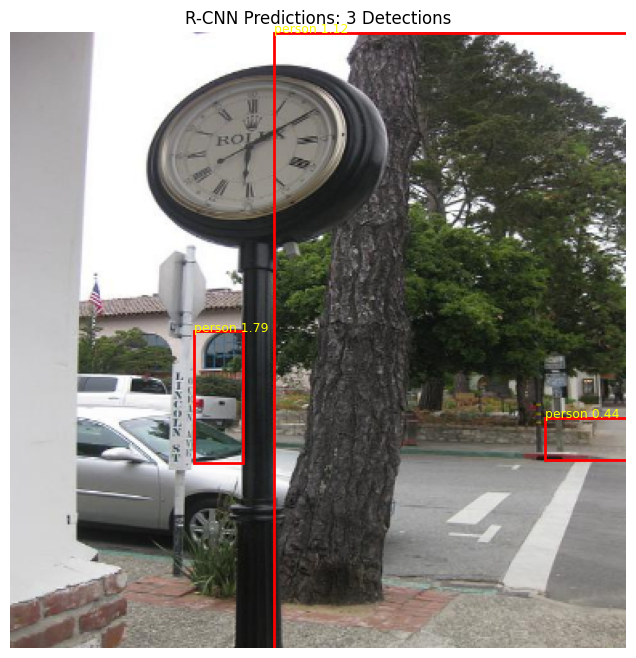

Total detections: 3


In [15]:

def detect(
    record,
    margin_threshold=0.0,
    nms_iou=0.30
):

    image, gt = prepare_image(record)

    boxes = selective_proposals(image)

    patches = []
    valid = []

    for box in boxes:

        x1, y1, x2, y2 = np.round(box).astype(int)

        if x2 - x1 >= 8 and y2 - y1 >= 8:

            patches.append(
                image[y1:y2, x1:x2]
            )

            valid.append(box)

    if not patches:
        return image, gt, []

    X = extract_features(patches)

    classes = svm.named_steps["linearsvc"].classes_

    pred = svm.predict(X)

    margins = svm.decision_function(X)

    if margins.ndim == 1:

        scores = np.where(
            pred == classes[1],
            margins,
            -margins
        )

    else:

        indices = np.array([
            np.where(classes == c)[0][0]
            for c in pred
        ])

        scores = margins[
            np.arange(len(pred)),
            indices
        ]

    detections = []

    for cls in classes:

        if cls == BACKGROUND:
            continue

        ids = [
            i for i in range(len(pred))
            if pred[i] == cls
            and scores[i] >= margin_threshold
        ]

        if not ids:
            continue

        class_boxes = np.array([
            valid[i] for i in ids
        ])

        class_scores = np.array([
            scores[i] for i in ids
        ])

        selected = nms(
            class_boxes,
            class_scores,
            nms_iou
        )

        for j in selected:

            detections.append({
                "box": class_boxes[j],
                "class": int(cls),
                "score": float(class_scores[j])
            })

    return image, gt, detections


def show_detections(record, threshold=0.0):

    image, gt, detections = detect(
        record,
        margin_threshold=threshold
    )

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.imshow(image)

    for item in detections:

        x1, y1, x2, y2 = item["box"]

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor="red",
                linewidth=2
            )
        )

        ax.text(
            x1,
            y1,
            f"{COCO_CLASSES[item['class']]} {item['score']:.2f}",
            color="yellow",
            fontsize=9
        )

    ax.set_title(
        f"R-CNN Predictions: {len(detections)} Detections"
    )

    ax.axis("off")

    plt.savefig(
        "/content/rcnn_lab/final_detections.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    return detections


predictions = show_detections(
    test_records[0]
)

print("Total detections:", len(predictions))


# **Evaluate Object Detection**

In [16]:

import pandas as pd

# Run detection on all test images
results = []

for rec in tqdm(test_records, desc="Evaluating test images"):

    _, gt, detections = detect(rec)

    results.append((gt, detections))


def evaluate_class(
    results,
    cls,
    iou_threshold=0.5
):

    # Ground-truth boxes for this class only
    gt_by_image = {
        i: [
            box for box, class_id in gt
            if class_id == cls
        ]
        for i, (gt, _) in enumerate(results)
    }

    total_gt = sum(
        len(boxes)
        for boxes in gt_by_image.values()
    )

    if total_gt == 0:
        return None

    # Collect predictions for this class
    ranked = []

    for image_id, (_, detections) in enumerate(results):

        for detection in detections:

            if detection["class"] == cls:

                ranked.append((
                    detection["score"],
                    image_id,
                    detection["box"]
                ))

    ranked.sort(
        key=lambda item: item[0],
        reverse=True
    )

    matched = {
        i: set()
        for i in gt_by_image
    }

    tp = []
    fp = []

    for score, image_id, box in ranked:

        gt_boxes = gt_by_image[image_id]

        matches = [
            iou(box, gt_box)
            if j not in matched[image_id]
            else -1

            for j, gt_box in enumerate(gt_boxes)
        ]

        j = int(np.argmax(matches)) if matches else -1

        good = (
            j >= 0
            and matches[j] >= iou_threshold
        )

        if good:

            matched[image_id].add(j)

        tp.append(int(good))
        fp.append(int(not good))

    if not tp:

        return {
            "class": COCO_CLASSES[cls],
            "gt": total_gt,
            "detections": 0,
            "precision": 0.0,
            "recall": 0.0,
            "AP50": 0.0
        }

    tp = np.cumsum(tp)
    fp = np.cumsum(fp)

    recall = tp / total_gt

    precision = tp / np.maximum(
        tp + fp,
        1
    )

    # Precision envelope
    r = np.r_[0.0, recall, 1.0]
    p = np.r_[0.0, precision, 0.0]

    for k in range(len(p) - 2, -1, -1):

        p[k] = max(
            p[k],
            p[k + 1]
        )

    changes = np.where(
        r[1:] != r[:-1]
    )[0]

    ap = float(
        np.sum(
            (r[changes + 1] - r[changes])
            * p[changes + 1]
        )
    )

    return {
        "class": COCO_CLASSES[cls],
        "gt": total_gt,
        "detections": len(ranked),
        "precision": float(precision[-1]),
        "recall": float(recall[-1]),
        "AP50": ap
    }


# Evaluate all represented test classes
rows = [
    evaluate_class(results, cls)
    for cls in COCO_CLASSES
]

# Exclude classes with no ground-truth objects in the test set
rows = [
    row for row in rows
    if row is not None
]

summary = pd.DataFrame(rows)

display(summary)

if len(summary) > 0:

    mean_ap = float(
        summary["AP50"].mean()
    )

    print(
        "mAP@0.5:",
        round(mean_ap, 3)
    )

else:

    print("No represented classes found in the test set.")


Evaluating test images:   0%|          | 0/10 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

... (3 outputs left out)

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/4 [00:00<?, ?it/s]

,class,gt,detections,precision,recall,AP50
0,person,53,119,0.033613,0.075472,0.008238
1,car,1,3,0.000000,0.000000,0.000000
2,dog,1,1,0.000000,0.000000,0.000000


mAP@0.5: 0.003


In [17]:

summary.to_csv(
    "/content/rcnn_lab/detection_evaluation.csv",
    index=False
)

print("Evaluation table saved successfully.")


Evaluation table saved successfully.


# **Visualize Precision and Recall**

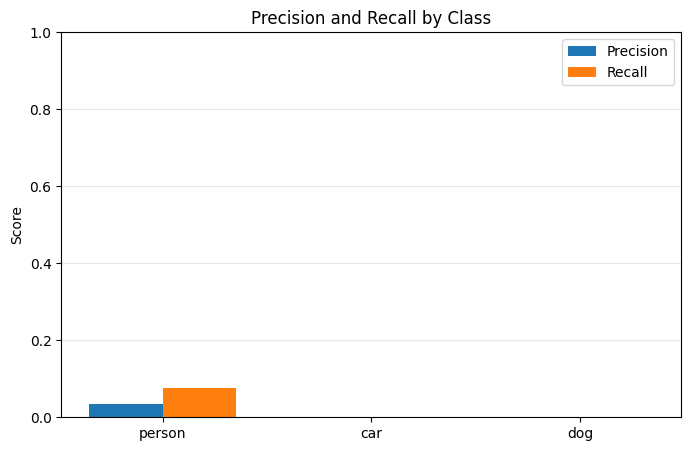

In [18]:

if len(summary) > 0:

    fig, ax = plt.subplots(figsize=(8, 5))

    x = np.arange(len(summary))
    width = 0.35

    ax.bar(
        x - width / 2,
        summary["precision"],
        width,
        label="Precision"
    )

    ax.bar(
        x + width / 2,
        summary["recall"],
        width,
        label="Recall"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(summary["class"])

    ax.set_ylim(0, 1)

    ax.set_ylabel("Score")
    ax.set_title("Precision and Recall by Class")

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.savefig(
        "/content/rcnn_lab/precision_recall.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


# **Final Results and Discussion**

### Experimental Results

The R-CNN pipeline was evaluated using a subset of the COCO128 dataset.

The experiment includes three object categories:
Person, Car, and Dog.

The system uses Selective Search for region proposals,
ResNet18 for CNN feature extraction, and Linear SVM
for region classification.

Non-Maximum Suppression is applied to reduce overlapping
detections.

The final performance is reported using Precision,
Recall, AP@0.5, and mAP@0.5.